## 0. Research design and reproducibility

In [ ]:
# Install only the libraries needed by this notebook
!pip -q install requests pandas numpy matplotlib seaborn scikit-learn tqdm

In [ ]:
import os, re, io, json, gzip, time, math, random, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("/content/ASSETWISE_AI")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())

Project directory: /content/ASSETWISE_AI
Execution timestamp (UTC): 2026-11-16T08:38:50.795030+00:00


### 0.1 Configure the study window

NVD's CVE API supports publication-date filtering. Keep the window within the API's permitted date-range limit (the default below is 30 days). If you need a broader historical dataset, use the official NVD JSON 2.0 year feeds or query separate date windows and document the extraction procedure.

For a first working run, leave the defaults unchanged.

In [ ]:
# EDIT THESE SETTINGS BEFORE RUNNING
END_DATE = datetime.now(timezone.utc).date()
START_DATE = END_DATE - timedelta(days=30)
NVD_RESULTS_PER_PAGE = 2000
MAX_NVD_PAGES = None          # None = retrieve all pages in the selected date window
NVD_API_KEY = ""              # Optional: paste your NVD API key here; keep it private
REQUEST_TIMEOUT = 60
REQUEST_PAUSE_SECONDS = 6     # Conservative delay between NVD requests without an API key

print(f"NVD publication window: {START_DATE} to {END_DATE}")

NVD publication window: 2026-10-17 to 2026-11-16


## 1. Download public source datasets

The notebook downloads the current EPSS daily bulk CSV and current CISA KEV JSON feed. It retrieves NVD CVEs published within the configured date window. The exact retrieval timestamp, NVD window, EPSS score date (when provided in the file metadata), and KEV catalogue version are retained for reproducibility.

In [ ]:
NVD_API_URL = "https://services.nvd.nist.gov/rest/json/cves/2.0"
EPSS_URL = "https://epss.empiricalsecurity.com/epss_scores-current.csv.gz"
KEV_URL = "https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json"

session = requests.Session()
session.headers.update({"User-Agent": "ASSETWISE-AI-Research-Notebook/1.0"})
if NVD_API_KEY.strip():
    session.headers["apiKey"] = NVD_API_KEY.strip()

def download_bytes(url, timeout=REQUEST_TIMEOUT):
    response = session.get(url, timeout=timeout)
    response.raise_for_status()
    return response.content

retrieval_time_utc = datetime.now(timezone.utc).isoformat()

print("Downloading EPSS daily CSV...")
epss_bytes = download_bytes(EPSS_URL)
(DATA_DIR / "epss_scores-current.csv.gz").write_bytes(epss_bytes)
print(f"EPSS compressed bytes: {len(epss_bytes):,}")

print("Downloading CISA KEV JSON...")
kev_bytes = download_bytes(KEV_URL)
(DATA_DIR / "known_exploited_vulnerabilities.json").write_bytes(kev_bytes)
kev_payload = json.loads(kev_bytes.decode("utf-8"))
print("KEV catalogue version:", kev_payload.get("catalogVersion"))
print("KEV release date:", kev_payload.get("dateReleased"))
print("KEV entries:", len(kev_payload.get("vulnerabilities", [])))

EPSS compressed bytes: 2,849,232
KEV catalogue version: 2026.11.13
KEV release date: 2026-11-13T20:24:18.3008Z
KEV entries: 1781


### 1.1 Retrieve NVD CVEs with pagination and retry handling

In [ ]:
def nvd_get_page(params, max_retries=5):
    headers = {}
    for attempt in range(max_retries):
        try:
            response = session.get(NVD_API_URL, params=params, headers=headers, timeout=REQUEST_TIMEOUT)
            if response.status_code in (429, 503):
                wait = min(30 * (attempt + 1), 120)
                print(f"NVD returned {response.status_code}; waiting {wait}s...")
                time.sleep(wait)
                continue
            response.raise_for_status()
            return response.json()
        except requests.RequestException:
            if attempt == max_retries - 1:
                raise
            time.sleep(min(10 * (attempt + 1), 60))
    raise RuntimeError("NVD request failed after retries")

def fetch_nvd_cves(start_date, end_date, page_size=2000, max_pages=None):
    # NVD date filters are UTC timestamps; date-only input is expanded to full UTC days.
    start_iso = datetime.combine(start_date, datetime.min.time(), tzinfo=timezone.utc)
    end_iso = datetime.combine(end_date, datetime.max.time(), tzinfo=timezone.utc)
    if (end_iso - start_iso).days > 120:
        raise ValueError("Please split NVD queries into windows of 120 days or less.")
    start_index = 0
    all_items = []
    total = None
    page = 0
    while True:
        params = {
            "pubStartDate": start_iso.strftime("%Y-%m-%dT%H:%M:%S.000Z"),
            "pubEndDate": end_iso.strftime("%Y-%m-%dT%H:%M:%S.000Z"),
            "resultsPerPage": page_size,
            "startIndex": start_index
        }
        payload = nvd_get_page(params)
        vulnerabilities = payload.get("vulnerabilities", [])
        all_items.extend(vulnerabilities)
        total = payload.get("totalResults", len(all_items))
        page += 1
        print(f"Fetched page {page}: {len(vulnerabilities)} records; {len(all_items)}/{total}")
        if not vulnerabilities or len(all_items) >= total:
            break
        if max_pages is not None and page >= max_pages:
            print("Stopped at MAX_NVD_PAGES. Increase it or set None to retrieve all pages.")
            break
        start_index += len(vulnerabilities)
        time.sleep(REQUEST_PAUSE_SECONDS if not NVD_API_KEY.strip() else 0.7)
    return all_items

nvd_raw = fetch_nvd_cves(START_DATE, END_DATE, NVD_RESULTS_PER_PAGE, MAX_NVD_PAGES)
print("Total NVD CVE records retrieved:", len(nvd_raw))
(DATA_DIR / "nvd_raw_window.json").write_text(json.dumps(nvd_raw, indent=2), encoding="utf-8")

Fetched page 1: 2000 records; 2000/16702
NVD returned 503; waiting 30s...
Fetched page 2: 2000 records; 4000/16702
Fetched page 3: 2000 records; 6000/16702
NVD returned 503; waiting 30s...
Fetched page 4: 2000 records; 8000/16702
Fetched page 5: 2000 records; 10000/16702
Fetched page 6: 2000 records; 12000/16702
Fetched page 7: 2000 records; 14000/16702
Fetched page 8: 2000 records; 16000/16702
NVD returned 503; waiting 30s...
Fetched page 9: 702 records; 16702/16702
Total NVD CVE records retrieved: 16702


85212009

## 2. Parse and standardise NVD, EPSS and KEV

In [ ]:
def first_metric(metrics, keys):
    for key in keys:
        values = metrics.get(key, [])
        if values:
            # Prefer NVD's primary metric entry when present.
            chosen = next((x for x in values if x.get("type") == "Primary"), values[0])
            data = chosen.get("cvssData", {})
            return {
                "cvss_score": data.get("baseScore"),
                "cvss_severity": data.get("baseSeverity") or chosen.get("baseSeverity"),
                "cvss_version": data.get("version"),
                "attack_vector": data.get("attackVector"),
                "attack_complexity": data.get("attackComplexity"),
                "privileges_required": data.get("privilegesRequired"),
                "user_interaction": data.get("userInteraction"),
                "scope": data.get("scope"),
                "confidentiality_impact": data.get("confidentialityImpact"),
                "integrity_impact": data.get("integrityImpact"),
                "availability_impact": data.get("availabilityImpact")
            }
    return {k: None for k in [
        "cvss_score","cvss_severity","cvss_version","attack_vector",
        "attack_complexity","privileges_required","user_interaction","scope",
        "confidentiality_impact","integrity_impact","availability_impact"
    ]}

def parse_nvd_item(item):
    cve = item.get("cve", {})
    descriptions = cve.get("descriptions", [])
    description = next((d.get("value") for d in descriptions if d.get("lang") == "en"), "")
    metrics = cve.get("metrics", {})
    metric = first_metric(metrics, ["cvssMetricV40", "cvssMetricV31", "cvssMetricV30", "cvssMetricV2"])
    weaknesses = []
    for weakness in cve.get("weaknesses", []):
        for desc in weakness.get("description", []):
            if desc.get("lang") == "en":
                weaknesses.append(desc.get("value"))
    products = []
    for config in cve.get("configurations", []):
        for node in config.get("nodes", []):
            for match in node.get("cpeMatch", []):
                criteria = match.get("criteria")
                if criteria:
                    products.append(criteria)
    return {
        "cve": cve.get("id"),
        "published": cve.get("published"),
        "last_modified": cve.get("lastModified"),
        "vuln_status": cve.get("vulnStatus"),
        "description": description,
        "weaknesses": ";".join(sorted(set(weaknesses))),
        "cpe_matches": ";".join(sorted(set(products))[:20]),
        **metric
    }

nvd_df = pd.DataFrame([parse_nvd_item(x) for x in nvd_raw])
nvd_df = nvd_df.dropna(subset=["cve"]).drop_duplicates("cve")
nvd_df["published"] = pd.to_datetime(nvd_df["published"], utc=True, errors="coerce")
nvd_df["last_modified"] = pd.to_datetime(nvd_df["last_modified"], utc=True, errors="coerce")
nvd_df["cvss_score"] = pd.to_numeric(nvd_df["cvss_score"], errors="coerce")
print("Parsed NVD shape:", nvd_df.shape)
display(nvd_df.head(3))

Parsed NVD shape: (16702, 18)


,cve,published,last_modified,vuln_status,description,weaknesses,cpe_matches,cvss_score,cvss_severity,cvss_version,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality_impact,integrity_impact,availability_impact
0,CVE-2026-111823,2026-10-17 02:17:18.470000+00:00,2026-10-19 21:14:14.150000+00:00,Deferred,Mage OSS through 0.9.80 before 76c4f46 can pro...,CWE-390,,9.8,CRITICAL,3.1,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
1,CVE-2026-111853,2026-10-17 02:17:18.610000+00:00,2026-10-19 21:14:14.150000+00:00,Deferred,An issue was discovered on Tektronix 3 Series ...,CWE-78,,8.8,HIGH,3.1,NETWORK,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,HIGH
2,CVE-2026-111854,2026-10-17 02:17:18.750000+00:00,2026-10-19 22:17:03.853000+00:00,Awaiting Analysis,An issue was discovered on Tektronix 3 Series ...,CWE-22,,8.1,HIGH,3.1,NETWORK,LOW,LOW,NONE,UNCHANGED,HIGH,HIGH,NONE


In [ ]:
# EPSS CSV may begin with a metadata comment line. pandas comment="#" skips it.
epss_df = pd.read_csv(io.BytesIO(epss_bytes), compression="gzip", comment="#")
epss_df.columns = [c.strip().lower() for c in epss_df.columns]
epss_df = epss_df.rename(columns={"cve": "cve", "epss": "epss", "percentile": "epss_percentile"})
epss_df["epss"] = pd.to_numeric(epss_df["epss"], errors="coerce")
epss_df["epss_percentile"] = pd.to_numeric(epss_df["epss_percentile"], errors="coerce")
epss_df = epss_df.drop_duplicates("cve")
print("EPSS rows:", len(epss_df))
display(epss_df.head(3))

kev_df = pd.DataFrame(kev_payload.get("vulnerabilities", []))
kev_df = kev_df.rename(columns={"cveID": "cve"})
if "cve" not in kev_df:
    kev_df["cve"] = pd.Series(dtype="object")
kev_df["kev"] = 1
print("KEV rows:", len(kev_df))
display(kev_df.head(3))

EPSS rows: 406615


,cve,epss,epss_percentile
0,CVE-1999-0001,0.04753,0.92024
1,CVE-1999-0002,0.27858,0.98124
2,CVE-1999-0003,0.24380,0.97900


KEV rows: 1781


,cve,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes,kev
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,UnrealIRCd Improper Neutralization of Delimite...,2026-11-13,UnrealIRCd UnrealIRCd contains an improper neu...,Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://forums.unrealircd.org/viewtopic.php?t=...,[CWE-140],1
1,CVE-2026-123039,Check Point,Multiple Products,Check Point Multiple Products Incorrect Permis...,2026-11-13,"Check Point Firewall, Multi-Domain Security Ma...",Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://support.checkpoint.com/results/sk/sk10...,"[CWE-732, CWE-862]",1
2,CVE-2026-124194,Microsoft,Office,Microsoft Office Outlook Missing User Interact...,2026-11-10,Microsoft Office Outlook contains a missing us...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://msrc.microsoft.com/update-guide/en-US/...,[CWE-356],1


## 3. Merge public vulnerability intelligence

In [ ]:
# Left join EPSS and KEV to the NVD publication-window cohort.
# A missing EPSS score is retained as missing, not silently treated as zero.
public_df = nvd_df.merge(
    epss_df[["cve", "epss", "epss_percentile"]],
    on="cve", how="left", validate="one_to_one"
)
kev_columns = ["cve", "kev", "vendorProject", "product", "dateAdded",
               "dueDate", "knownRansomwareCampaignUse", "requiredAction"]
kev_keep = [c for c in kev_columns if c in kev_df.columns]
public_df = public_df.merge(kev_df[kev_keep], on="cve", how="left", validate="one_to_one")
public_df["kev"] = public_df["kev"].fillna(0).astype(int)
public_df["epss_missing"] = public_df["epss"].isna().astype(int)
public_df["cvss_missing"] = public_df["cvss_score"].isna().astype(int)
public_df["kev_status"] = np.where(public_df["kev"].eq(1), "KEV-listed", "Not-listed-in-current-KEV")
public_df["data_source_label"] = "REAL_PUBLIC"
public_df["retrieved_at_utc"] = retrieval_time_utc
public_df["nvd_window_start"] = str(START_DATE)
public_df["nvd_window_end"] = str(END_DATE)
public_df["kev_catalog_version"] = kev_payload.get("catalogVersion")
public_df["kev_date_released"] = kev_payload.get("dateReleased")

print("Merged cohort:", public_df.shape)
print("CVSS missing:", int(public_df["cvss_missing"].sum()))
print("EPSS missing:", int(public_df["epss_missing"].sum()))
print("KEV listed in cohort:", int(public_df["kev"].sum()))
display(public_df[["cve","published","cvss_score","cvss_severity","epss","epss_percentile","kev","description"]].head(10))

Merged cohort: (16702, 36)
CVSS missing: 1573
EPSS missing: 740
KEV listed in cohort: 18


,cve,published,cvss_score,cvss_severity,epss,epss_percentile,kev,description
0,CVE-2026-111823,2026-10-17 02:17:18.470000+00:00,9.8,CRITICAL,0.00556,0.46915,0,Mage OSS through 0.9.80 before 76c4f46 can pro...
1,CVE-2026-111853,2026-10-17 02:17:18.610000+00:00,8.8,HIGH,0.01034,0.64384,0,An issue was discovered on Tektronix 3 Series ...
2,CVE-2026-111854,2026-10-17 02:17:18.750000+00:00,8.1,HIGH,0.00476,0.41687,0,An issue was discovered on Tektronix 3 Series ...
3,CVE-2026-111855,2026-10-17 02:17:18.877000+00:00,7.5,HIGH,0.00608,0.49707,0,An issue was discovered on Tektronix 3 Series ...
4,CVE-2026-104734,2026-10-17 03:16:27.927000+00:00,7.2,HIGH,0.00452,0.39806,0,"The Kirki – Freeform Page Builder, Website Bui..."
5,CVE-2026-107762,2026-10-17 03:16:28.083000+00:00,7.5,HIGH,0.00396,0.34301,0,"The Kirki – Freeform Page Builder, Website Bui..."
6,CVE-2026-107763,2026-10-17 03:16:28.213000+00:00,4.3,MEDIUM,0.00213,0.11696,0,The Fastcache by Host.it plugin for WordPress ...
7,CVE-2026-109208,2026-10-17 03:16:28.340000+00:00,7.2,HIGH,0.00285,0.21227,0,The LearnPress – WordPress LMS Plugin for Crea...
8,CVE-2026-110653,2026-10-17 03:16:28.480000+00:00,9.1,CRITICAL,0.00403,0.35080,0,The Appointment Booking Plugin – LatePoint | C...
9,CVE-2026-111601,2026-10-17 03:16:28.613000+00:00,6.1,MEDIUM,0.00226,0.13457,0,The Hippoo Mobile App for WooCommerce plugin f...


### 3.1 Dataset quality checks and provenance

In [ ]:
quality_report = pd.DataFrame({
    "field": public_df.columns,
    "dtype": [str(public_df[c].dtype) for c in public_df.columns],
    "missing_count": [int(public_df[c].isna().sum()) for c in public_df.columns],
    "missing_percent": [round(public_df[c].isna().mean()*100, 2) for c in public_df.columns]
}).sort_values("missing_percent", ascending=False)
display(quality_report.head(20))
print("Unique CVEs:", public_df["cve"].nunique())
print("Duplicate CVE rows:", int(public_df["cve"].duplicated().sum()))
print("EPSS outside [0,1]:", int((~public_df["epss"].dropna().between(0,1)).sum()))
print("CVSS outside [0,10]:", int((~public_df["cvss_score"].dropna().between(0,10)).sum()))

,field,dtype,missing_count,missing_percent
26,requiredAction,object,16684,99.89
25,knownRansomwareCampaignUse,object,16684,99.89
23,dateAdded,object,16684,99.89
24,dueDate,object,16684,99.89
22,product,object,16684,99.89
21,vendorProject,object,16684,99.89
16,integrity_impact,object,6497,38.90
17,availability_impact,object,6497,38.90
14,scope,object,6497,38.90
15,confidentiality_impact,object,6497,38.90


Unique CVEs: 16702
Duplicate CVE rows: 0
EPSS outside [0,1]: 0
CVSS outside [0,10]: 0


## 4. Exploratory data analysis (EDA)

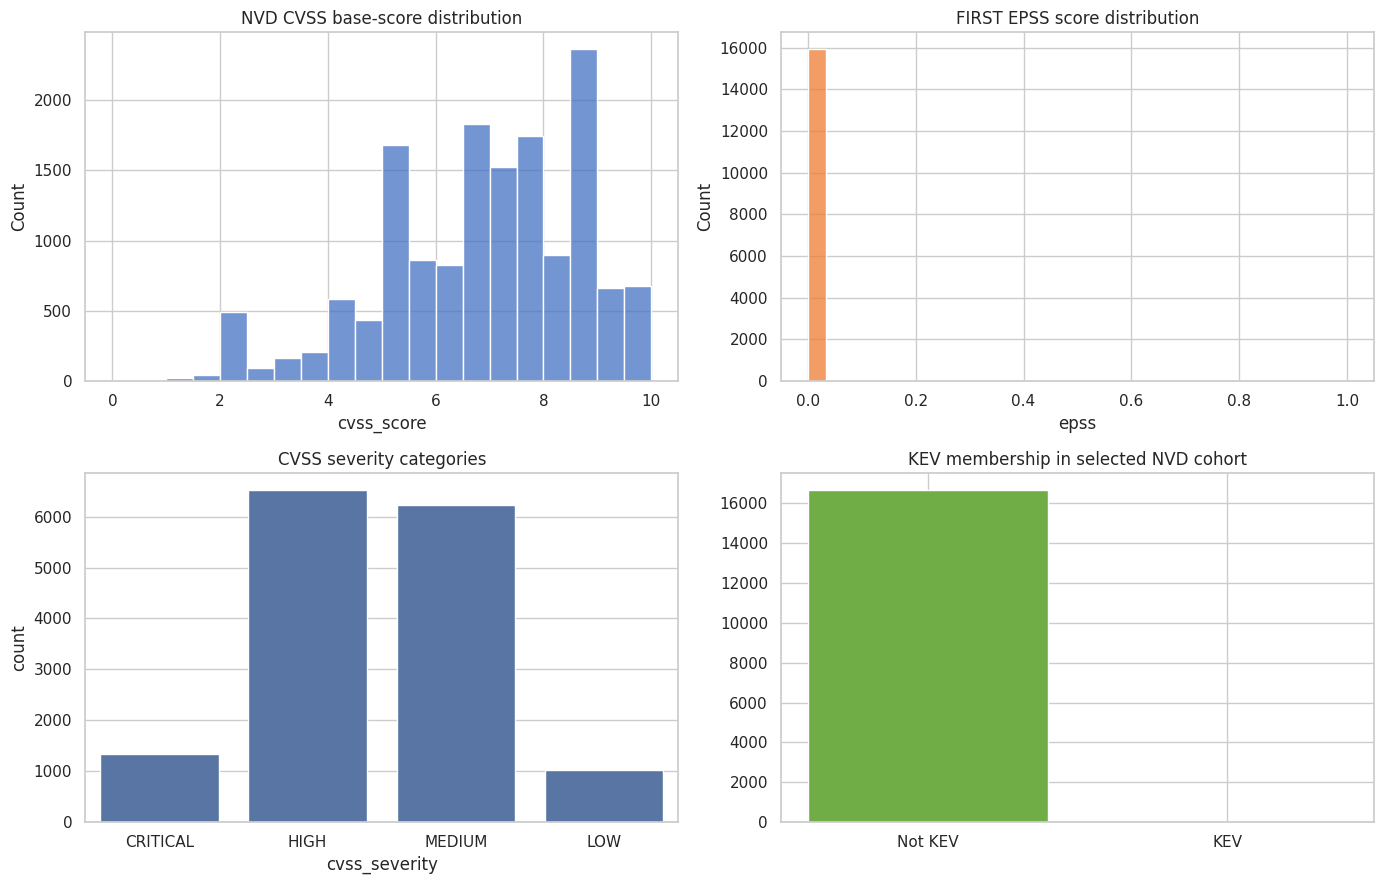

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(public_df["cvss_score"].dropna(), bins=20, ax=axes[0,0], color="#4472C4")
axes[0,0].set_title("NVD CVSS base-score distribution")
sns.histplot(public_df["epss"].dropna(), bins=30, ax=axes[0,1], color="#ED7D31")
axes[0,1].set_title("FIRST EPSS score distribution")
sns.countplot(data=public_df, x="cvss_severity", order=["CRITICAL","HIGH","MEDIUM","LOW"], ax=axes[1,0])
axes[1,0].set_title("CVSS severity categories")
axes[1,1].bar(["Not KEV","KEV"], [int((public_df.kev==0).sum()), int((public_df.kev==1).sum())],
              color=["#70AD47","#C00000"])
axes[1,1].set_title("KEV membership in selected NVD cohort")
plt.tight_layout()
plt.show()

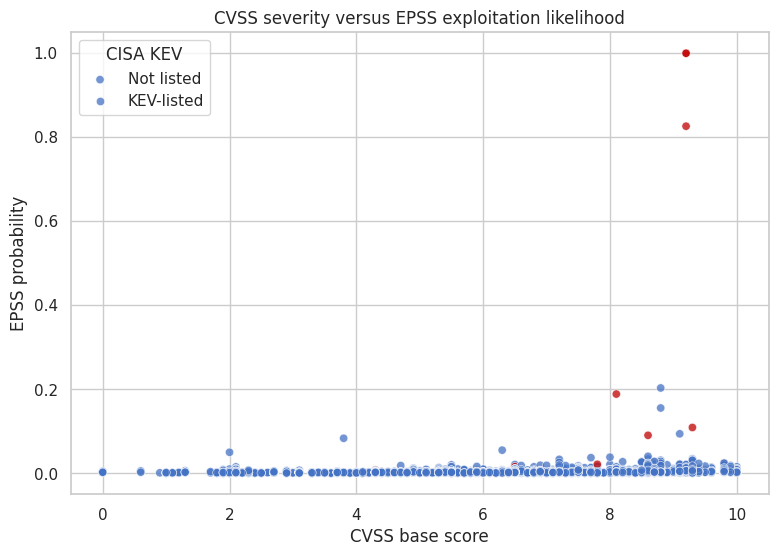

In [ ]:
# CVSS and EPSS are different concepts: severity versus estimated exploitation likelihood.
plot_df = public_df.dropna(subset=["cvss_score","epss"])
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="cvss_score", y="epss", hue="kev", palette={0:"#4472C4",1:"#C00000"}, alpha=.75)
plt.title("CVSS severity versus EPSS exploitation likelihood")
plt.xlabel("CVSS base score")
plt.ylabel("EPSS probability")
plt.legend(title="CISA KEV", labels=["Not listed","KEV-listed"])
plt.show()

## 5. Build a synthetic asset-context layer

NVD, EPSS and KEV describe vulnerabilities and threat intelligence; they do not tell us which assets in a particular organisation are affected, how critical those assets are, or whether the asset inventory is stale. To test the research question, this notebook creates **synthetic asset records** and attaches sampled CVEs to them. The asset fields are explicitly labelled `SYNTHETIC`; do not present them as observed enterprise data.

In [ ]:
# Create synthetic asset records with reproducible values.
ASSET_COUNT = max(30, min(250, len(public_df) // 3 if len(public_df) else 30))
rng = np.random.default_rng(SEED)
business_functions = ["Payment processing","Customer portal","Internal operations","Research","Remote access","Data storage"]
asset_types = ["Server","Web application","Database","Network appliance","Workstation","IoT device"]
network_zones = ["DMZ","Internal","Restricted","OT-Lab"]
owners = ["IT Security","Infrastructure","Application Team","Research Lab","Network Team"]

assets = pd.DataFrame({
    "asset_id": [f"ASSET-{i:04d}" for i in range(1, ASSET_COUNT+1)],
    "asset_name": [f"Synthetic asset {i:03d}" for i in range(1, ASSET_COUNT+1)],
    "asset_type": rng.choice(asset_types, ASSET_COUNT),
    "business_function": rng.choice(business_functions, ASSET_COUNT),
    "criticality": rng.integers(1, 6, ASSET_COUNT).astype(float),
    "internet_exposure": rng.choice([0,1], ASSET_COUNT, p=[.65,.35]).astype(float),
    "network_zone": rng.choice(network_zones, ASSET_COUNT),
    "owner": rng.choice(owners, ASSET_COUNT),
    "last_verified_days": rng.integers(1, 240, ASSET_COUNT),
    "source": "SYNTHETIC"
})
display(assets.head())
print("Synthetic asset records:", len(assets))

,asset_id,asset_name,asset_type,business_function,criticality,internet_exposure,network_zone,owner,last_verified_days,source
0,ASSET-0001,Synthetic asset 001,Server,Customer portal,1.0,0.0,DMZ,Application Team,223,SYNTHETIC
1,ASSET-0002,Synthetic asset 002,Workstation,Internal operations,4.0,1.0,Internal,Infrastructure,213,SYNTHETIC
2,ASSET-0003,Synthetic asset 003,Network appliance,Customer portal,5.0,0.0,DMZ,Infrastructure,151,SYNTHETIC
3,ASSET-0004,Synthetic asset 004,Database,Customer portal,5.0,0.0,OT-Lab,Infrastructure,95,SYNTHETIC
4,ASSET-0005,Synthetic asset 005,Database,Research,2.0,1.0,Restricted,Application Team,150,SYNTHETIC


Synthetic asset records: 250


In [ ]:
# Attach each CVE to one synthetic asset for controlled per-asset ranking experiments.
# This mapping is simulated and is NOT evidence that the asset runs the affected product.
if public_df.empty:
    raise ValueError("No NVD CVEs were retrieved. Check connectivity or widen the NVD date window.")
vuln_assets = public_df.copy()
vuln_assets["asset_id"] = rng.choice(assets["asset_id"], size=len(vuln_assets), replace=True)
vuln_assets = vuln_assets.merge(assets, on="asset_id", how="left", validate="many_to_one")
vuln_assets["asset_context_label"] = "SYNTHETIC"
vuln_assets["record_label"] = "REAL_PUBLIC vulnerability fields + SYNTHETIC asset context"
display(vuln_assets[["cve","cvss_score","epss","kev","asset_id","criticality","internet_exposure","last_verified_days"]].head())

,cve,cvss_score,epss,kev,asset_id,criticality,internet_exposure,last_verified_days
0,CVE-2026-111823,9.8,0.00556,0,ASSET-0220,3.0,0.0,37
1,CVE-2026-111853,8.8,0.01034,0,ASSET-0016,1.0,0.0,224
2,CVE-2026-111854,8.1,0.00476,0,ASSET-0100,4.0,0.0,40
3,CVE-2026-111855,7.5,0.00608,0,ASSET-0115,4.0,0.0,200
4,CVE-2026-104734,7.2,0.00452,0,ASSET-0200,1.0,1.0,77


## 6. Data-quality intelligence

In [ ]:
STALE_AFTER_DAYS = 90

def classify_asset_quality(row):
    issues = []
    if pd.isna(row.get("criticality")): issues.append("missing_criticality")
    if pd.isna(row.get("internet_exposure")): issues.append("missing_exposure")
    age = row.get("last_verified_days")
    if pd.isna(age) or age > STALE_AFTER_DAYS: issues.append("stale_context")
    return pd.Series({
        "quality_issue_count": len(issues),
        "quality_issues": ";".join(issues) if issues else "none",
        "asset_data_quality": "UNRELIABLE" if issues else "COMPLETE"
    })

asset_quality = assets.join(assets.apply(classify_asset_quality, axis=1))
display(asset_quality["asset_data_quality"].value_counts().rename_axis("quality").to_frame("assets"))

,assets
quality,
UNRELIABLE,142
COMPLETE,108


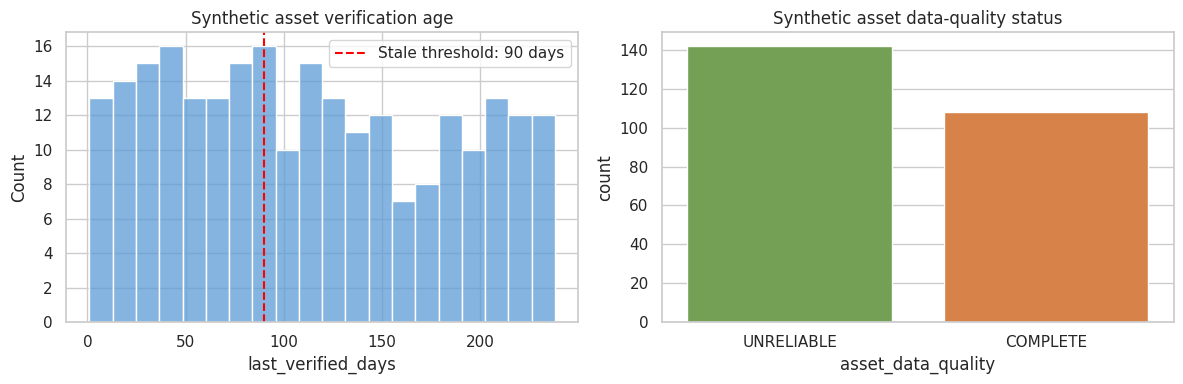

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(assets["last_verified_days"], bins=20, ax=axes[0], color="#5B9BD5")
axes[0].axvline(STALE_AFTER_DAYS, color="red", linestyle="--", label=f"Stale threshold: {STALE_AFTER_DAYS} days")
axes[0].legend()
axes[0].set_title("Synthetic asset verification age")
sns.countplot(data=asset_quality, x="asset_data_quality", ax=axes[1], palette=["#70AD47","#ED7D31"])
axes[1].set_title("Synthetic asset data-quality status")
plt.tight_layout()
plt.show()

## 7. Baseline vulnerability prioritisation

The following baselines are transparent ranking rules, not trained predictive models:
1. CVSS-only severity.
2. EPSS-only exploitation likelihood.
3. KEV-first rule.
4. Combined CVSS + EPSS + KEV.
5. Context-aware illustrative score using asset criticality and internet exposure.

The weights below are a **research starting point**. They must be justified, stress-tested and compared in the final study. A score should not be described as a calibrated probability of compromise.

In [ ]:
def minmax01(series):
    s = pd.to_numeric(series, errors="coerce")
    if s.notna().sum() == 0: return pd.Series(0.0, index=s.index)
    lo, hi = s.min(), s.max()
    if pd.isna(lo) or pd.isna(hi) or hi == lo:
        return pd.Series(0.0, index=s.index)
    return (s - lo) / (hi - lo)

rank_df = vuln_assets.copy()
rank_df["cvss_norm"] = rank_df["cvss_score"].fillna(0) / 10.0
rank_df["epss_filled"] = rank_df["epss"].fillna(rank_df["epss"].median() if rank_df["epss"].notna().any() else 0)
rank_df["criticality_norm"] = (rank_df["criticality"].fillna(3) - 1) / 4
rank_df["exposure_filled"] = rank_df["internet_exposure"].fillna(.5)

rank_df["score_cvss"] = 100 * rank_df["cvss_norm"]
rank_df["score_epss"] = 100 * rank_df["epss_filled"]
rank_df["score_kev"] = 80 * rank_df["kev"] + 20 * rank_df["cvss_norm"]
rank_df["score_combined"] = (
    40 * rank_df["cvss_norm"] + 35 * rank_df["epss_filled"] + 25 * rank_df["kev"]
)
rank_df["score_assetwise"] = (
    30 * rank_df["cvss_norm"] + 25 * rank_df["epss_filled"] +
    20 * rank_df["kev"] + 15 * rank_df["criticality_norm"] +
    10 * rank_df["exposure_filled"]
)

score_columns = ["score_cvss","score_epss","score_kev","score_combined","score_assetwise"]
for col in score_columns:
    rank_df[col.replace("score_","rank_")] = rank_df[col].rank(method="average", ascending=False)

display(rank_df.sort_values("score_assetwise", ascending=False)[
    ["cve","cvss_score","epss","kev","criticality","internet_exposure","score_assetwise"]
].head(15))

,cve,cvss_score,epss,kev,criticality,internet_exposure,score_assetwise
3394,CVE-2026-109619,9.2,0.99999,1,4.0,0.0,83.84975
3393,CVE-2026-109618,9.2,0.99999,1,1.0,0.0,72.59975
8645,CVE-2026-111560,8.6,0.09082,1,4.0,1.0,69.32050
3913,CVE-2026-111497,9.2,0.82641,1,1.0,0.0,68.26025
10744,CVE-2026-116779,9.8,0.02473,1,5.0,0.0,65.01825
11891,CVE-2026-114713,8.6,0.00508,1,5.0,0.0,60.92700
8646,CVE-2026-116606,9.3,0.10947,1,1.0,1.0,60.63675
4135,CVE-2026-114625,9.4,0.01025,1,1.0,1.0,58.45625
8321,CVE-2026-119977,8.1,0.01199,1,2.0,1.0,58.34975
11197,CVE-2026-19868,7.5,0.00532,1,5.0,0.0,57.63300


In [ ]:
# Compare the top-K CVEs selected by each baseline.
TOP_K = 10
topk_sets = {c: set(rank_df.nlargest(TOP_K, c)["cve"]) for c in score_columns}
overlap_rows = []
for i, a in enumerate(score_columns):
    for b in score_columns[i+1:]:
        overlap_rows.append({"baseline_A":a.replace("score_",""),"baseline_B":b.replace("score_",""),
                             "topK_overlap":len(topk_sets[a] & topk_sets[b]),
                             "jaccard":len(topk_sets[a] & topk_sets[b]) / max(1,len(topk_sets[a] | topk_sets[b]))})
overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)

,baseline_A,baseline_B,topK_overlap,jaccard
0,cvss,epss,0,0.000000
1,cvss,kev,0,0.000000
2,cvss,combined,0,0.000000
3,cvss,assetwise,0,0.000000
4,epss,kev,4,0.250000
5,epss,combined,6,0.428571
6,epss,assetwise,5,0.333333
7,kev,combined,8,0.666667
8,kev,assetwise,6,0.428571
9,combined,assetwise,7,0.538462


## 8. Scenario-based asset-context degradation

For each Monte Carlo scenario, the complete synthetic reference asset inventory is perturbed with one or more defect mechanisms:
- **Missing:** criticality or exposure is removed.
- **Stale:** a field is replaced by a plausible older/alternate value.
- **Conflicting:** the field is replaced with a contradictory source value.

The score uses an explicit neutral fallback for missing context. The scenario generator records the mechanism and random seed. This is a controlled simulation, not a claim about the real-world frequency of these defects.

In [ ]:
def score_with_context(base, criticality, exposure):
    # base carries public CVE attributes; missing values use neutral fallbacks.
    crit = 3.0 if pd.isna(criticality) else float(criticality)
    exp = .5 if pd.isna(exposure) else float(exposure)
    crit_norm = (crit - 1) / 4
    cvss_norm = float(base["cvss_norm"])
    epss_value = float(base["epss_filled"])
    kev_value = int(base["kev"])
    return 30*cvss_norm + 25*epss_value + 20*kev_value + 15*crit_norm + 10*exp

def simulate_rank_stability(data, asset_table, degradation=.30, scenarios=200,
                            top_k=10, defect="mixed", seed=42):
    rng_local = np.random.default_rng(seed)
    valid_defects = ["missing","stale","conflict"]
    mechanisms = valid_defects if defect == "mixed" else [defect]
    asset_lookup = asset_table.set_index("asset_id")
    rank_records = []
    for scenario_id in range(scenarios):
        perturbed = {}
        mechanism_log = []
        for asset_id, a in asset_lookup.iterrows():
            crit = a["criticality"]
            exposure = a["internet_exposure"]
            if rng_local.random() < degradation:
                mechanism = rng_local.choice(mechanisms)
                mechanism_log.append(mechanism)
                if mechanism == "missing":
                    if rng_local.random() < .5: crit = np.nan
                    else: exposure = np.nan
                elif mechanism == "stale":
                    if rng_local.random() < .5:
                        crit = float(np.clip(crit + rng_local.choice([-2,-1,1,2]), 1, 5))
                    else:
                        exposure = 1 - float(exposure)
                elif mechanism == "conflict":
                    crit = float(rng_local.choice([1,2,4,5]))
                    exposure = float(rng_local.choice([0,1]))
            perturbed[asset_id] = (crit, exposure)
        scores = []
        for _, row in data.iterrows():
            crit, exp = perturbed[row["asset_id"]]
            scores.append(score_with_context(row, crit, exp))
        tmp = pd.DataFrame({"cve":data["cve"].values,"score":scores})
        tmp["rank"] = tmp["score"].rank(method="first", ascending=False).astype(int)
        tmp["scenario"] = scenario_id
        rank_records.append(tmp[["cve","rank","score","scenario"]])
    long = pd.concat(rank_records, ignore_index=True)
    stability = long.groupby("cve").agg(
        median_rank=("rank","median"),
        min_rank=("rank","min"),
        max_rank=("rank","max"),
        rank_std=("rank","std"),
        mean_score=("score","mean")
    ).reset_index()
    inclusion = (long.assign(in_top_k=long["rank"] <= top_k)
                 .groupby("cve")["in_top_k"].mean().rename("topk_inclusion_probability"))
    stability = stability.merge(inclusion, on="cve", how="left")
    stability["rank_std"] = stability["rank_std"].fillna(0)
    stability["empirical_rank_range"] = stability["max_rank"] - stability["min_rank"]
    stability["review_flag"] = np.where(
        (stability["topk_inclusion_probability"] < .70) &
        (stability["mean_score"] >= 50), "REVIEW", "NO_FLAG"
    )
    return stability.sort_values(["topk_inclusion_probability","median_rank"],
                                 ascending=[False,True]), long

stability_df, scenario_ranks = simulate_rank_stability(
    rank_df, assets, degradation=.30, scenarios=200, top_k=TOP_K,
    defect="mixed", seed=SEED
)
display(stability_df.head(20))

,cve,median_rank,min_rank,max_rank,rank_std,mean_score,topk_inclusion_probability,empirical_rank_range,review_flag
2256,CVE-2026-109619,1.0,1,3,0.356948,84.13725,1.000,2,NO_FLAG
2255,CVE-2026-109618,2.0,1,4,0.637973,75.06225,1.000,3,NO_FLAG
2747,CVE-2026-111497,4.0,1,6,1.162695,71.16650,1.000,5,NO_FLAG
2762,CVE-2026-111560,4.0,2,550,67.903711,67.67675,0.965,548,NO_FLAG
5947,CVE-2026-116779,5.0,1,477,42.242719,64.52450,0.935,476,NO_FLAG
4949,CVE-2026-114713,7.0,3,1321,122.941000,61.07075,0.905,1318,NO_FLAG
5816,CVE-2026-116606,7.0,2,382,78.904177,60.79925,0.890,380,NO_FLAG
4891,CVE-2026-114625,9.0,4,661,137.065439,57.82500,0.745,657,NO_FLAG
7775,CVE-2026-119977,9.0,3,1547,267.345803,57.48100,0.710,1544,NO_FLAG
11757,CVE-2026-19868,10.0,5,2009,266.067506,57.77675,0.560,2004,REVIEW


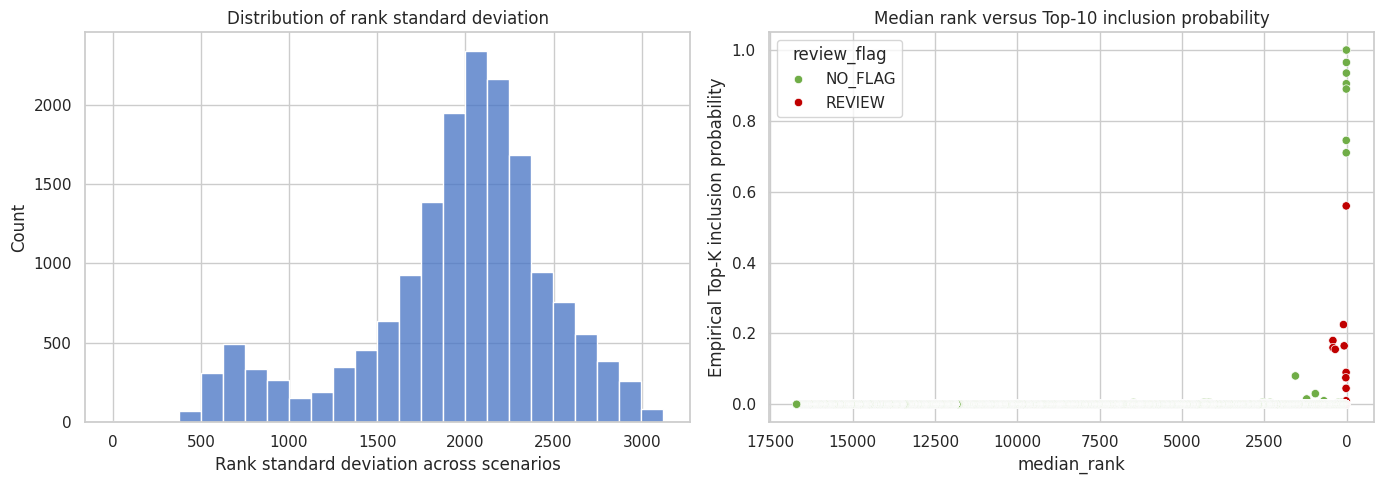

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.histplot(stability_df["rank_std"], bins=25, ax=axes[0], color="#4472C4")
axes[0].set_title("Distribution of rank standard deviation")
axes[0].set_xlabel("Rank standard deviation across scenarios")
sns.scatterplot(data=stability_df, x="median_rank", y="topk_inclusion_probability",
                hue="review_flag", ax=axes[1], palette={"REVIEW":"#C00000","NO_FLAG":"#70AD47"})
axes[1].invert_xaxis()
axes[1].set_title(f"Median rank versus Top-{TOP_K} inclusion probability")
axes[1].set_ylabel("Empirical Top-K inclusion probability")
plt.tight_layout()
plt.show()

## 9. Compare defect mechanisms and degradation levels

In [ ]:
def run_sensitivity(data, asset_table, degradation_levels=(0,.1,.2,.3,.5,.7),
                    scenarios=100, top_k=10, seed=42):
    outputs = []
    for defect in ["missing","stale","conflict","mixed"]:
        for level in degradation_levels:
            stab, _ = simulate_rank_stability(
                data, asset_table, degradation=level, scenarios=scenarios,
                top_k=top_k, defect=defect, seed=seed
            )
            outputs.append({
                "defect": defect,
                "degradation": level,
                "mean_rank_std": stab["rank_std"].mean(),
                "median_rank_std": stab["rank_std"].median(),
                "mean_topk_probability": stab["topk_inclusion_probability"].mean(),
                "review_fraction": (stab["review_flag"]=="REVIEW").mean()
            })
    return pd.DataFrame(outputs)

sensitivity_df = run_sensitivity(rank_df, assets, scenarios=100, top_k=TOP_K, seed=SEED)
display(sensitivity_df)

,defect,degradation,mean_rank_std,median_rank_std,mean_topk_probability,review_fraction
0,missing,0.0,0.000000,0.000000,0.000599,0.023231
1,missing,0.1,703.590437,700.949080,0.000599,0.020477
2,missing,0.2,993.840873,1001.271468,0.000599,0.015806
3,missing,0.3,1207.932774,1221.525674,0.000599,0.008861
4,missing,0.5,1493.453677,1465.048556,0.000599,0.005329
5,missing,0.7,1651.364520,1548.766779,0.000599,0.003173
6,stale,0.0,0.000000,0.000000,0.000599,0.023231
7,stale,0.1,1085.777120,1132.003062,0.000599,0.019998
8,stale,0.2,1525.610794,1630.837510,0.000599,0.015088
9,stale,0.3,1828.668276,1994.420134,0.000599,0.008262


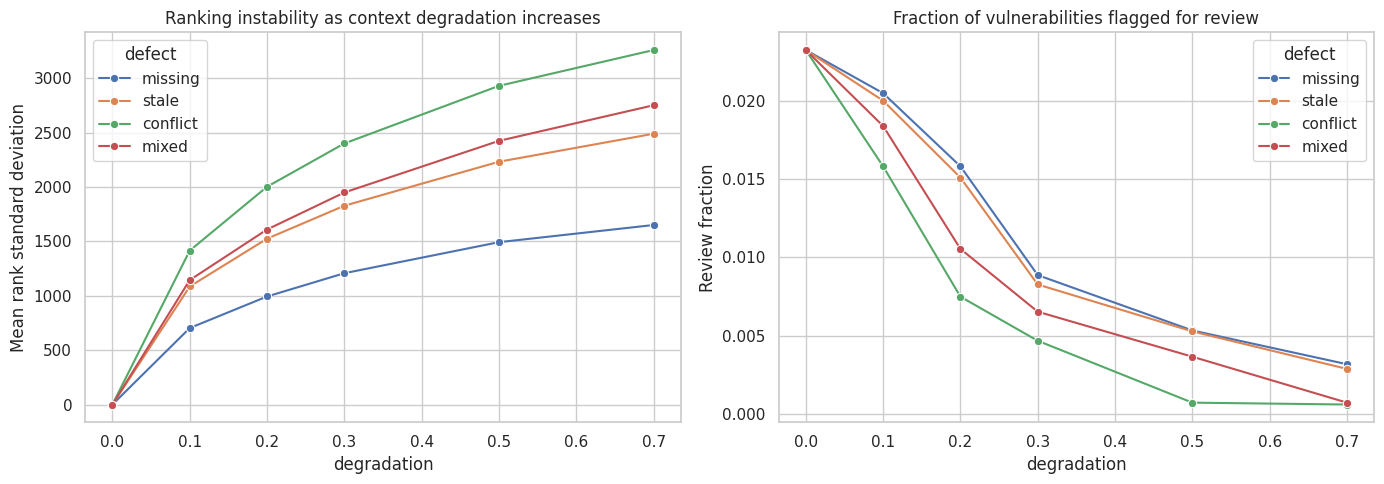

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.lineplot(data=sensitivity_df, x="degradation", y="mean_rank_std",
             hue="defect", marker="o", ax=axes[0])
axes[0].set_title("Ranking instability as context degradation increases")
axes[0].set_ylabel("Mean rank standard deviation")
sns.lineplot(data=sensitivity_df, x="degradation", y="review_fraction",
             hue="defect", marker="o", ax=axes[1])
axes[1].set_title("Fraction of vulnerabilities flagged for review")
axes[1].set_ylabel("Review fraction")
plt.tight_layout()
plt.show()

## 10. Ranking evaluation and ablation

Because this joined dataset does not provide an independent, per-asset ground-truth remediation label, the notebook does **not** claim supervised classification accuracy, ROC-AUC or PR-AUC. Instead it evaluates ordering behaviour and stability. KEV membership is an external threat-intelligence indicator, not a complete ground-truth exploit label. The ablation below compares the effect of adding asset context and scenario analysis to a fixed ranking cohort.

In [ ]:
from scipy.stats import kendalltau, spearmanr

def ranking_comparison(data, columns):
    rows=[]
    for i, col_a in enumerate(columns):
        for col_b in columns[i+1:]:
            a = data[col_a].rank(ascending=False, method="average")
            b = data[col_b].rank(ascending=False, method="average")
            tau = kendalltau(a,b,nan_policy="omit").statistic
            rho = spearmanr(a,b,nan_policy="omit").statistic
            set_a=set(data.nlargest(TOP_K, col_a)["cve"])
            set_b=set(data.nlargest(TOP_K, col_b)["cve"])
            rows.append({"ranking_A":col_a,"ranking_B":col_b,
                         "kendall_tau":tau,"spearman_rho":rho,
                         "topK_overlap":len(set_a & set_b)})
    return pd.DataFrame(rows)

rank_corr_df = ranking_comparison(rank_df, score_columns)
display(rank_corr_df)

,ranking_A,ranking_B,kendall_tau,spearman_rho,topK_overlap
0,score_cvss,score_epss,0.310027,0.453440,0
1,score_cvss,score_kev,0.999128,0.999465,0
2,score_cvss,score_combined,0.980627,0.998289,0
3,score_cvss,score_assetwise,0.495499,0.669500,0
4,score_epss,score_kev,0.310773,0.454253,4
5,score_epss,score_combined,0.341312,0.481392,6
6,score_epss,score_assetwise,0.195612,0.289117,5
7,score_kev,score_combined,0.981483,0.998824,8
8,score_kev,score_assetwise,0.496321,0.670299,6
9,score_combined,score_assetwise,0.490857,0.669419,7


In [ ]:
# Ablation: A = CVSS baseline; B = CVSS + EPSS + KEV; C = add point asset context;
# D = scenario-based uncertainty / review layer (reported as stability metrics).
ablation_rows = [
    {"stage":"A: CVSS only","ranking_score":"score_cvss",
     "mean_rank_std":np.nan,"mean_topk_probability":np.nan,
     "review_policy":"None"},
    {"stage":"B: CVSS + EPSS + KEV","ranking_score":"score_combined",
     "mean_rank_std":np.nan,"mean_topk_probability":np.nan,
     "review_policy":"None"},
    {"stage":"C: Add asset context","ranking_score":"score_assetwise",
     "mean_rank_std":stability_df["rank_std"].mean(),
     "mean_topk_probability":stability_df["topk_inclusion_probability"].mean(),
     "review_policy":"None"},
    {"stage":"D: Add scenario review","ranking_score":"score_assetwise",
     "mean_rank_std":stability_df["rank_std"].mean(),
     "mean_topk_probability":stability_df["topk_inclusion_probability"].mean(),
     "review_policy":f"{(stability_df.review_flag=='REVIEW').sum()} cases flagged"}
]
ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

,stage,ranking_score,mean_rank_std,mean_topk_probability,review_policy
0,A: CVSS only,score_cvss,NaN,NaN,None
1,B: CVSS + EPSS + KEV,score_combined,NaN,NaN,None
2,C: Add asset context,score_assetwise,1954.019008,0.000599,None
3,D: Add scenario review,score_assetwise,1954.019008,0.000599,110 cases flagged


## 11. Human-in-the-loop review queue

In [ ]:
review_queue = stability_df.merge(
    rank_df[["cve","description","cvss_score","epss","kev","asset_id","asset_name",
             "criticality","internet_exposure"]],
    on="cve", how="left"
)
review_queue = review_queue[
    (review_queue["review_flag"]=="REVIEW") |
    ((review_queue["kev"]==1) & (review_queue["topk_inclusion_probability"]<.9))
].sort_values(["kev","mean_score"], ascending=[False,False])

display(review_queue[[
    "cve","asset_name","mean_score","topk_inclusion_probability",
    "median_rank","rank_std","kev","review_flag"
]].head(25))

,cve,asset_name,mean_score,topk_inclusion_probability,median_rank,rank_std,kev,review_flag
6,CVE-2026-116606,Synthetic asset 088,60.79925,0.890,7.0,78.904177,1,NO_FLAG
7,CVE-2026-114625,Synthetic asset 046,57.82500,0.745,9.0,137.065439,1,NO_FLAG
9,CVE-2026-19868,Synthetic asset 024,57.77675,0.560,10.0,266.067506,1,REVIEW
8,CVE-2026-119977,Synthetic asset 248,57.48100,0.710,9.0,267.345803,1,NO_FLAG
10,CVE-2026-123158,Synthetic asset 235,55.02500,0.225,93.0,68.190056,1,REVIEW
12,CVE-2026-76418,Synthetic asset 129,54.88650,0.165,72.0,129.885218,1,REVIEW
17,CVE-2026-124194,Synthetic asset 065,54.61125,0.075,21.5,343.061029,1,REVIEW
11,CVE-2026-102895,Synthetic asset 207,52.62925,0.180,414.0,199.378375,1,REVIEW
80,CVE-2026-118527,Synthetic asset 234,52.40550,0.000,63.5,935.346377,1,REVIEW
13,CVE-2026-123218,Synthetic asset 221,52.31500,0.160,411.0,193.564046,1,REVIEW


## 12. Export reproducible datasets and results

In [ ]:
# Keep source-derived fields and synthetic/derived fields distinguishable.
public_export = public_df.copy()
asset_export = assets.copy()
merged_export = rank_df.copy()
stability_export = stability_df.copy()

public_export.to_csv(OUTPUT_DIR/"public_vulnerability_intelligence_nvd_epss_kev.csv", index=False)
asset_export.to_csv(OUTPUT_DIR/"synthetic_asset_inventory.csv", index=False)
merged_export.to_csv(OUTPUT_DIR/"joined_vulnerability_asset_context.csv", index=False)
stability_export.to_csv(OUTPUT_DIR/"scenario_rank_stability.csv", index=False)
sensitivity_df.to_csv(OUTPUT_DIR/"sensitivity_experiments.csv", index=False)
rank_corr_df.to_csv(OUTPUT_DIR/"ranking_comparison_metrics.csv", index=False)
review_queue.to_csv(OUTPUT_DIR/"human_review_queue.csv", index=False)

metadata = {
    "project": "ASSETWISE AI",
    "retrieved_at_utc": retrieval_time_utc,
    "nvd_publication_window_start": str(START_DATE),
    "nvd_publication_window_end": str(END_DATE),
    "nvd_records": int(len(nvd_df)),
    "epss_feed_url": EPSS_URL,
    "kev_feed_url": KEV_URL,
    "kev_catalog_version": kev_payload.get("catalogVersion"),
    "kev_date_released": kev_payload.get("dateReleased"),
    "asset_data": "SYNTHETIC",
    "random_seed": SEED,
    "scenario_count_main": 200,
    "degradation_main": 0.30,
    "top_k": TOP_K,
    "limitations": [
        "Synthetic asset inventory and CVE-to-asset mapping",
        "Illustrative scoring weights; not an industry standard",
        "Current EPSS/KEV snapshots are not historical snapshots aligned to each CVE publication date",
        "Scenario rank ranges are empirical, not calibrated confidence intervals",
        "KEV membership is not a complete ground-truth exploitation label"
    ]
}
(OUTPUT_DIR/"run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved outputs to:", OUTPUT_DIR)
print("\\n".join(sorted(p.name for p in OUTPUT_DIR.iterdir())))

Saved outputs to: /content/ASSETWISE_AI/outputs
human_review_queue.csv\njoined_vulnerability_asset_context.csv\npublic_vulnerability_intelligence_nvd_epss_kev.csv\nranking_comparison_metrics.csv\nrun_metadata.json\nscenario_rank_stability.csv\nsensitivity_experiments.csv\nsynthetic_asset_inventory.csv


## 13. Download results from Google Colab

In [ ]:
# Download a ZIP containing all CSV outputs and run metadata.
import shutil
zip_path = shutil.make_archive("/content/ASSETWISE_AI_results", "zip", OUTPUT_DIR)
print("Created:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Not running inside Google Colab. Download the ZIP from the file browser.")

Created: /content/ASSETWISE_AI_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Research interpretation and paper-ready reporting checklist

Before using any output in a report or journal manuscript:

1. **Freeze source snapshots.** Keep the exact NVD extraction window, EPSS file and KEV JSON used for the run.
2. **Check temporal alignment.** This notebook joins the current EPSS and KEV snapshots to a recent NVD cohort. That is suitable for a current-state prototype, but it is not a historical backtest. For historical claims, retrieve EPSS and KEV snapshots corresponding to each evaluation date and avoid future-information leakage.
3. **Verify asset-product applicability.** The current CVE-to-asset assignment is random and synthetic. A research-grade study must create a documented, plausible asset-product mapping or use an explicitly synthetic benchmark with known ground truth.
4. **Justify the scoring function.** Conduct sensitivity analysis over weights and compare with accepted baselines.
5. **Repeat random seeds.** Report mean, standard deviation and confidence intervals only where their statistical assumptions are justified.
6. **Distinguish descriptive uncertainty from calibrated uncertainty.** Empirical rank intervals over simulated scenarios are not automatically confidence intervals.
7. **Avoid unsupported novelty claims.** Compare the final method carefully with prior work on partial information, context-aware prioritisation, missing-data methods and uncertainty quantification.

### Suggested paper tables and figures
- Dataset and provenance summary.
- Missingness and asset data-quality profile.
- CVSS versus EPSS scatter plot with KEV overlay.
- Baseline top-K overlap and rank correlation.
- Rank distribution and Top-K inclusion probability.
- Sensitivity to missing, stale and conflicting context.
- Ablation of data-quality and scenario-analysis components.
- Human-review coverage and workload.

### Source documentation
- NVD API 2.0: https://nvd.nist.gov/developers/vulnerabilities
- FIRST EPSS data: https://www.first.org/epss/data
- FIRST EPSS FAQ: https://www.first.org/epss/faq
- CISA KEV catalogue: https://www.cisa.gov/known-exploited-vulnerabilities-catalog

**Attribution:** Cite NVD, FIRST EPSS and CISA KEV as data sources in your report. FIRST requests attribution when EPSS data is used. Follow each source's current terms and documentation.